In [1]:

!pip -q install psutil pandas matplotlib torchvision


In [2]:

import time
import os
import platform
import psutil
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt

from torchvision.models import resnet18, ResNet18_Weights

# Select available hardware
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Operating system:", platform.system())
print("CPU cores:", os.cpu_count())
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("GPU not available. Enable GPU in Runtime settings.")


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Operating system: Linux
CPU cores: 2
Selected device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:

# Load pretrained model
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model = model.to(device)
model.eval()

# Disable gradient calculations for inference
torch.set_grad_enabled(False)

print("Model loaded successfully!")
print("Model: ResNet-18")
print("Mode: Inference")
print("Execution device:", next(model.parameters()).device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


Model loaded successfully!
Model: ResNet-18
Mode: Inference
Execution device: cuda:0


In [4]:

def benchmark_inference(model, device, batch_size,
                        warmup=5, iterations=20):

    # Generate synthetic image inputs: batch x channels x height x width
    inputs = torch.randn(batch_size, 3, 224, 224, device=device)

    # Warm up the model
    with torch.inference_mode():
        for _ in range(warmup):
            _ = model(inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)

    # Measure execution time
    start = time.perf_counter()

    with torch.inference_mode():
        for _ in range(iterations):
            _ = model(inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    latency_ms = (total_time / iterations) * 1000
    throughput = (batch_size * iterations) / total_time

    if device.type == "cuda":
        peak_memory_mb = (
            torch.cuda.max_memory_allocated(device) / 1024**2
        )
    else:
        peak_memory_mb = None

    return {
        "Device": str(device),
        "Batch Size": batch_size,
        "Latency (ms/batch)": round(latency_ms, 3),
        "Latency (ms/image)": round(latency_ms / batch_size, 3),
        "Throughput (images/sec)": round(throughput, 2),
        "Peak GPU Memory (MB)": (
            round(peak_memory_mb, 2)
            if peak_memory_mb is not None else None
        )
    }

print("Benchmark function ready!")


Benchmark function ready!


In [5]:

results = []

# CPU benchmark
cpu_model = model.to("cpu")
cpu_device = torch.device("cpu")

print("Running CPU benchmarks...")

for batch in [1, 8, 16]:
    result = benchmark_inference(
        cpu_model, cpu_device, batch,
        warmup=2, iterations=10
    )
    results.append(result)
    print(result)

# GPU benchmark, if available
if torch.cuda.is_available():
    model = model.to("cuda")
    gpu_device = torch.device("cuda")

    print("\nRunning GPU benchmarks...")

    for batch in [1, 8, 16, 32]:
        try:
            result = benchmark_inference(
                model, gpu_device, batch,
                warmup=3, iterations=15
            )
            results.append(result)
            print(result)

        except torch.cuda.OutOfMemoryError:
            print(f"GPU memory limit reached at batch size {batch}")
            torch.cuda.empty_cache()
            break

# Store results in a table
df = pd.DataFrame(results)
display(df)


Running CPU benchmarks...
{'Device': 'cpu', 'Batch Size': 1, 'Latency (ms/batch)': 71.507, 'Latency (ms/image)': 71.507, 'Throughput (images/sec)': 13.98, 'Peak GPU Memory (MB)': None}
{'Device': 'cpu', 'Batch Size': 8, 'Latency (ms/batch)': 732.37, 'Latency (ms/image)': 91.546, 'Throughput (images/sec)': 10.92, 'Peak GPU Memory (MB)': None}
{'Device': 'cpu', 'Batch Size': 16, 'Latency (ms/batch)': 913.53, 'Latency (ms/image)': 57.096, 'Throughput (images/sec)': 17.51, 'Peak GPU Memory (MB)': None}

Running GPU benchmarks...
{'Device': 'cuda', 'Batch Size': 1, 'Latency (ms/batch)': 4.036, 'Latency (ms/image)': 4.036, 'Throughput (images/sec)': 247.77, 'Peak GPU Memory (MB)': 79.87}
{'Device': 'cuda', 'Batch Size': 8, 'Latency (ms/batch)': 13.173, 'Latency (ms/image)': 1.647, 'Throughput (images/sec)': 607.29, 'Peak GPU Memory (MB)': 106.41}
{'Device': 'cuda', 'Batch Size': 16, 'Latency (ms/batch)': 13.91, 'Latency (ms/image)': 0.869, 'Throughput (images/sec)': 1150.22, 'Peak GPU Memory

,Device,Batch Size,Latency (ms/batch),Latency (ms/image),Throughput (images/sec),Peak GPU Memory (MB)
0,cpu,1,71.507,71.507,13.98,NaN
1,cpu,8,732.370,91.546,10.92,NaN
2,cpu,16,913.530,57.096,17.51,NaN
3,cuda,1,4.036,4.036,247.77,79.87
4,cuda,8,13.173,1.647,607.29,106.41
5,cuda,16,13.910,0.869,1150.22,162.00
6,cuda,32,26.125,0.816,1224.90,267.19


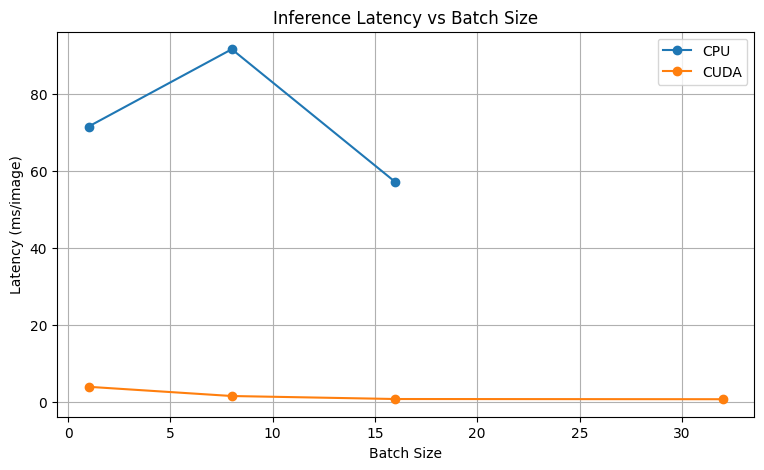

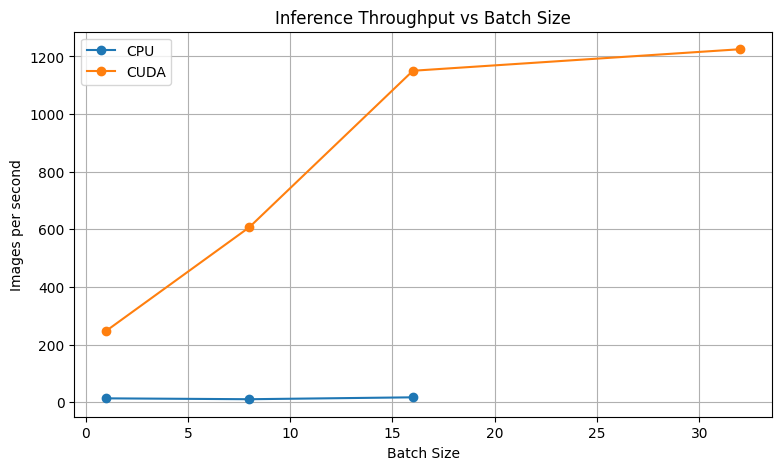

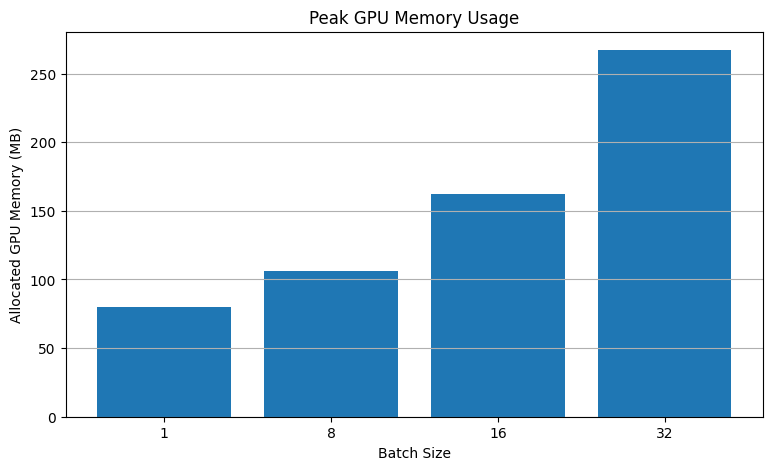

In [6]:

# Separate CPU and GPU results
cpu_results = df[df["Device"] == "cpu"]
gpu_results = df[df["Device"] == "cuda"]

# Chart 1: Latency per image
plt.figure(figsize=(9, 5))

for name, group in df.groupby("Device"):
    plt.plot(
        group["Batch Size"],
        group["Latency (ms/image)"],
        marker="o",
        label=name.upper()
    )

plt.title("Inference Latency vs Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Latency (ms/image)")
plt.legend()
plt.grid(True)
plt.show()

# Chart 2: Throughput
plt.figure(figsize=(9, 5))

for name, group in df.groupby("Device"):
    plt.plot(
        group["Batch Size"],
        group["Throughput (images/sec)"],
        marker="o",
        label=name.upper()
    )

plt.title("Inference Throughput vs Batch Size")
plt.xlabel("Batch Size")
plt.ylabel("Images per second")
plt.legend()
plt.grid(True)
plt.show()

# Chart 3: GPU memory consumption
if not gpu_results.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        gpu_results["Batch Size"].astype(str),
        gpu_results["Peak GPU Memory (MB)"]
    )
    plt.title("Peak GPU Memory Usage")
    plt.xlabel("Batch Size")
    plt.ylabel("Allocated GPU Memory (MB)")
    plt.grid(axis="y")
    plt.show()


In [7]:

print("===== SYSTEM-LEVEL BOTTLENECK ANALYSIS =====")

print("\n1. Hardware information")
print("CPU cores:", os.cpu_count())
print("System RAM used:", round(psutil.virtual_memory().percent, 2), "%")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated:",
          round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")
    print("GPU memory reserved:",
          round(torch.cuda.memory_reserved() / 1024**2, 2), "MB")

print("\n2. Performance observations")

for _, row in df.iterrows():
    print(
        f'{row["Device"].upper()}, batch={row["Batch Size"]}: '
        f'{row["Latency (ms/image)"]} ms/image, '
        f'{row["Throughput (images/sec)"]} images/sec'
    )

# Compare CPU and GPU at matching batch sizes
cpu_by_batch = cpu_results.set_index("Batch Size")
gpu_by_batch = gpu_results.set_index("Batch Size")

common_batches = sorted(
    set(cpu_by_batch.index) & set(gpu_by_batch.index)
)

print("\n3. CPU vs GPU comparison")

if common_batches:
    for batch in common_batches:
        cpu_time = cpu_by_batch.loc[batch, "Latency (ms/image)"]
        gpu_time = gpu_by_batch.loc[batch, "Latency (ms/image)"]

        if gpu_time > 0:
            speedup = cpu_time / gpu_time
            print(
                f"Batch {batch}: GPU speedup = {speedup:.2f}x"
            )
else:
    print("No matching CPU/GPU batch sizes available.")

print("\n4. Potential bottleneck indicators")

if not gpu_results.empty:
    gpu_max = gpu_results["Throughput (images/sec)"].max()
    gpu_min = gpu_results["Throughput (images/sec)"].min()

    if gpu_max > gpu_min:
        print("Throughput changes with batch size; batching may improve efficiency.")

    max_memory = gpu_results["Peak GPU Memory (MB)"].max()
    total_memory = (
        torch.cuda.get_device_properties(0).total_memory / 1024**2
    )

    print("Peak measured model memory:", round(max_memory, 2), "MB")
    print("Total physical GPU memory:", round(total_memory, 2), "MB")

print("\nNote: GPU utilization, data transfer time, and CPU input")
print("pipeline time should be measured separately for stronger conclusions.")


===== SYSTEM-LEVEL BOTTLENECK ANALYSIS =====

1. Hardware information
CPU cores: 2
System RAM used: 17.9 %
GPU: Tesla T4
GPU memory allocated: 52.82 MB
GPU memory reserved: 446.0 MB

2. Performance observations
CPU, batch=1: 71.507 ms/image, 13.98 images/sec
CPU, batch=8: 91.546 ms/image, 10.92 images/sec
CPU, batch=16: 57.096 ms/image, 17.51 images/sec
CUDA, batch=1: 4.036 ms/image, 247.77 images/sec
CUDA, batch=8: 1.647 ms/image, 607.29 images/sec
CUDA, batch=16: 0.869 ms/image, 1150.22 images/sec
CUDA, batch=32: 0.816 ms/image, 1224.9 images/sec

3. CPU vs GPU comparison
Batch 1: GPU speedup = 17.72x
Batch 8: GPU speedup = 55.58x
Batch 16: GPU speedup = 65.70x

4. Potential bottleneck indicators
Throughput changes with batch size; batching may improve efficiency.
Peak measured model memory: 267.19 MB
Total physical GPU memory: 14912.69 MB

Note: GPU utilization, data transfer time, and CPU input
pipeline time should be measured separately for stronger conclusions.


In [8]:

if torch.cuda.is_available():
    !nvidia-smi
else:
    print("No NVIDIA GPU available in this runtime.")


Thu Nov 26 03:30:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P0             34W /   70W |     579MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:

output_file = "gpu_inference_benchmark.csv"

df.to_csv(output_file, index=False)

print("Benchmark results saved to:", output_file)

from google.colab import files
files.download(output_file)


Benchmark results saved to: gpu_inference_benchmark.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>